# MLOps Lab Notebook (U23ADP17)
**4-Day Intensive Course: Hands-on code for all 5 units**

| Day | Units | Notebook sections |
|---|---|---|
| Day 1 | Unit I + Unit II (first half) | Section 1, Section 2 |
| Day 2 | Unit II (second half) + Unit III | Section 2 (cont.), Section 3 |
| Day 3 | Unit IV + Unit V | Section 4, Section 5 |
| Day 4 | Final assessment + project | Section 6 |

Run the cells **top to bottom**. Everything is kept small and simple so it runs on a laptop or Google Colab.

In [1]:
# Install everything needed (run once)
!pip install -q scikit-learn pandas numpy scipy matplotlib joblib mlflow dvc skl2onnx onnxruntime pytest

^C


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.61.1 requires python-multipart<1,>=0.0.10, but you have python-multipart 0.0.9 which is incompatible.
streamlit 1.61.1 requires starlette<1.4.0,>=0.46.0, but you have starlette 0.37.2 which is incompatible.
streamlit 1.61.1 requires uvicorn<1,>=0.30.0, but you have uvicorn 0.29.0 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# Common imports and a clean working folder for the whole lab
import os, sys, json, time, shutil, logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# Ensure Git/Bash tools are discoverable on Windows
if os.path.exists(r"C:\Program Files\Git\bin") and r"C:\Program Files\Git\bin" not in os.environ.get("PATH", ""):
    os.environ["PATH"] = r"C:\Program Files\Git\bin;" + os.environ.get("PATH", "")

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

WORK = "mlops_lab"
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)                    # every command below runs inside this folder
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)
print("Working folder:", os.getcwd())

Working folder: D:\study\mlops\mlops_lab


---
# Section 1: Introduction to MLOps (Unit I)

**Topics:** MLOps vs DevOps, challenges (data drift, model decay, scalability), maturity levels, key components, tools.

### MLOps vs DevOps
| | DevOps | MLOps |
|---|---|---|
| Versioned artifacts | Code | Code + **Data** + **Model** |
| Testing | Unit / integration | Plus data and model tests |
| Deployment | Ship an app | Ship a model, then **monitor and retrain** |
| Failure mode | Bugs | Bugs + **data drift, model decay** |

### Maturity levels
* **Level 0, Manual:** notebooks, manual deploy
* **Level 1, CI/CD:** automated tests and deployment
* **Level 2, Automated:** automated retraining, monitoring, orchestration

### Key components
**DataOps** (data pipelines, versioning) | **ModelOps** (training, tracking, registry) | **DevOps** (CI/CD, containers, infra)

### Tools overview
MLflow (tracking, registry), Kubeflow (pipelines on Kubernetes), TFX (TensorFlow production pipelines), DVC (data versioning), Airflow (orchestration), Evidently (monitoring).

### 1.1 Challenge demo: model decay caused by data drift
We train a model, then feed it data whose distribution has shifted. Watch the accuracy drop.

Accuracy on normal data  : 0.89
Accuracy on drifted data : 0.49


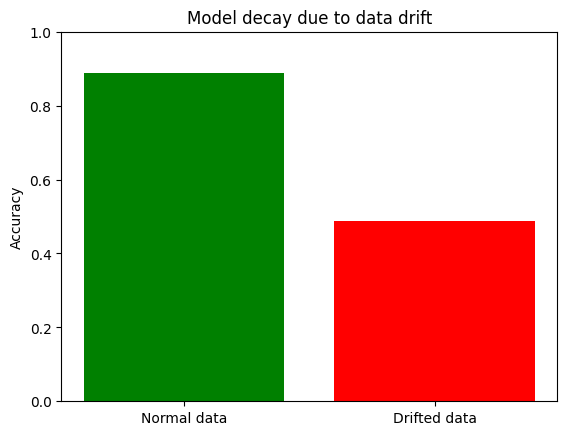

In [2]:
# Load IRIS.csv from D:/study/IRIS.csv (or local workspace)
data_path = "D:/study/IRIS.csv" if os.path.exists("D:/study/IRIS.csv") else ("../IRIS.csv" if os.path.exists("../IRIS.csv") else "IRIS.csv")
df_raw = pd.read_csv(data_path)

# Separate features and target using exact IRIS.csv column names
feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X, y = df_raw[feature_cols], df_raw["Species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=50, random_state=42).fit(X_train, y_train)
acc_normal = accuracy_score(y_test, model.predict(X_test))

# Simulate "production" data that has drifted: every feature shifts and gets noisier
rng = np.random.default_rng(0)
X_drifted = X_test + rng.normal(loc=1.0, scale=0.6, size=X_test.shape)
acc_drifted = accuracy_score(y_test, model.predict(X_drifted))

print(f"Accuracy on normal data  : {acc_normal:.2f}")
print(f"Accuracy on drifted data : {acc_drifted:.2f}")

plt.bar(["Normal data", "Drifted data"], [acc_normal, acc_drifted], color=["green", "red"])
plt.ylabel("Accuracy"); plt.title("Model decay due to data drift"); plt.ylim(0, 1)
plt.show()

### 1.2 Challenge demo: scalability
Training time grows with data size. This is why we later look at parallel and distributed training (Section 5).

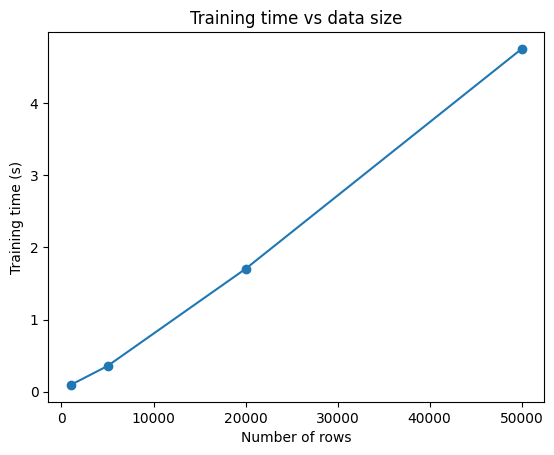

In [3]:
sizes = [1_000, 5_000, 20_000, 50_000]
times = []
for n in sizes:
    Xb = np.random.rand(n, 10)
    yb = (Xb.sum(axis=1) > 5).astype(int)
    t0 = time.time()
    RandomForestClassifier(n_estimators=30, random_state=0).fit(Xb, yb)
    times.append(time.time() - t0)

plt.plot(sizes, times, marker="o")
plt.xlabel("Number of rows"); plt.ylabel("Training time (s)"); plt.title("Training time vs data size")
plt.show()

---
# Section 2: Data and Model Management (Unit II)

**Topics:** data versioning (DVC), feature stores, model versioning (MLflow), experiment tracking, reproducibility with Docker.

### 2.1 Data versioning with DVC
DVC keeps big data files out of Git. Git stores a tiny `.dvc` pointer file, DVC stores the real data.
First we save the dataset as a CSV.

In [4]:
df = df_raw.copy()
df.to_csv("data/iris.csv", index=False)
print("Saved to data/iris.csv with shape:", df.shape)
df.head()

Saved to data/iris.csv with shape: (150, 5)
Out[4]: 
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm Species
0            5.1           3.5            1.4           0.2  setosa
1            4.9           3.0            1.4           0.2  setosa
2            4.7           3.2            1.3           0.2  setosa
3            4.6           3.1            1.5           0.2  setosa
4            5.0           3.6            1.4           0.2  setosa


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
%%bash
# Initialise Git and DVC, then version data v1
git init -q
git config user.email "student@example.com"
git config user.name "Student"
dvc init -q --no-scm 2>/dev/null || dvc init -q 2>/dev/null || true
dvc config core.analytics false
dvc add data/iris.csv
git add data/iris.csv.dvc data/.gitignore .dvc .dvcignore 2>/dev/null || git add data/iris.csv.dvc
git commit -q -m "Add dataset v1" || true
git tag -f v1
echo "---- Data v1 committed ----"
git log --oneline -n 3

---- Data v1 committed ----
c21ae34 Add dataset v1


Now we **change the data** (add 30 new rows) and save it as version 2.

In [6]:
new_rows = df.sample(30, random_state=1)
df2 = pd.concat([df, new_rows], ignore_index=True)
df2.to_csv("data/iris.csv", index=False)
print("Rows now:", len(df2))

Rows now: 180


In [7]:
%%bash
dvc add data/iris.csv
git add data/iris.csv.dvc
git commit -q -m "Add dataset v2 (30 new rows)" || true
git tag -f v2
git log --oneline -n 3

bb7f9b1 Add dataset v2 (30 new rows)
c21ae34 Add dataset v1


**Time travel:** go back to data v1 and confirm the file really changed back.

In [8]:
%%bash
git checkout -q v1 -- data/iris.csv.dvc
dvc checkout data/iris.csv.dvc
echo "Rows in data/iris.csv at v1 (+1 header line):"
wc -l data/iris.csv

M       data\iris.csv
Rows in data/iris.csv at v1 (+1 header line):
151 data/iris.csv


In [9]:
%%bash
git checkout -q v2 -- data/iris.csv.dvc
dvc checkout data/iris.csv.dvc
echo "Rows in data/iris.csv at v2 (+1 header line):"
wc -l data/iris.csv

M       data\iris.csv
Rows in data/iris.csv at v2 (+1 header line):
181 data/iris.csv


### 2.2 Feature store (simple version)
A **feature store** is a central place where features are computed once and reused for both training and serving.
Real tools: **Feast**, **Hopsworks**. Below is a tiny pandas-based store to show the idea.

In [10]:
class MiniFeatureStore:
    def __init__(self):
        self.features = {}                     # name -> DataFrame indexed by entity_id

    def register(self, name, df):
        self.features[name] = df
        print(f"Registered feature set '{name}' with {df.shape[1]} features and {len(df)} entities")

    def get_training_features(self, name):
        return self.features[name]

    def get_online_features(self, name, entity_id):
        return self.features[name].loc[entity_id]

raw = pd.read_csv("data/iris.csv")
raw["entity_id"] = range(len(raw))
fe = raw.set_index("entity_id")
fe["petal_area"] = fe["PetalLengthCm"] * fe["PetalWidthCm"]        # engineered feature
fe["sepal_ratio"] = fe["SepalLengthCm"] / fe["SepalWidthCm"]       # engineered feature

store = MiniFeatureStore()
store.register("iris_features", fe.drop(columns="Species"))
print("\nOnline lookup for entity 5:")
print(store.get_online_features("iris_features", 5))

Registered feature set 'iris_features' with 6 features and 180 entities

Online lookup for entity 5:
SepalLengthCm    5.400000
SepalWidthCm     3.900000
PetalLengthCm    1.700000
PetalWidthCm     0.400000
petal_area       0.680000
sepal_ratio      1.384615
Name: 5, dtype: float64


### 2.3 Experiment tracking and model versioning with MLflow
MLflow records **parameters, metrics, artifacts and models** for every run, so experiments can be compared and reproduced.
We use a local SQLite database so the **model registry** works too.

In [11]:
import mlflow, mlflow.sklearn
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("iris-experiments")

data = store.get_training_features("iris_features")
y_all = fe["Species"]
Xtr, Xte, ytr, yte = train_test_split(data, y_all, test_size=0.3, random_state=42, stratify=y_all)

configs = [
    {"n_estimators": 10,  "max_depth": 2},
    {"n_estimators": 50,  "max_depth": 4},
    {"n_estimators": 100, "max_depth": 8},
]

run_ids = []
for cfg in configs:
    with mlflow.start_run(run_name=f"rf_{cfg['n_estimators']}_{cfg['max_depth']}") as run:
        mdl = RandomForestClassifier(**cfg, random_state=42).fit(Xtr, ytr)
        acc = accuracy_score(yte, mdl.predict(Xte))
        mlflow.log_params(cfg)                       # hyperparameters
        mlflow.log_metric("accuracy", acc)           # metric
        mlflow.log_param("data_version", "v2")       # link run to data version
        mlflow.sklearn.log_model(mdl, "model", serialization_format="cloudpickle")   # model artifact
        run_ids.append(run.info.run_id)
        print(cfg, "-> accuracy", round(acc, 4))

{'n_estimators': 10, 'max_depth': 2} -> accuracy 0.9444
{'n_estimators': 50, 'max_depth': 4} -> accuracy 0.9444
{'n_estimators': 100, 'max_depth': 8} -> accuracy 0.9444


2026/10/28 10:24:15 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Kavibalan.R\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.
2026/10/28 10:24:18 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/28 10:24:18 INFO mlflow.store.db.utils: Updating database tables
2026/10/28 10:24:21 INFO mlflow.tracking.fluent: Experiment with name 'iris-experiments' does not exist. Creating a new experiment.
2026/10/28 10:24:22 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/28 10:24:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary co

In [12]:
# Compare all runs in a table
runs = mlflow.search_runs(order_by=["metrics.accuracy DESC"])
runs[["tags.mlflow.runName", "params.n_estimators", "params.max_depth", "metrics.accuracy"]]

Out[12]: 
  tags.mlflow.runName params.n_estimators params.max_depth  metrics.accuracy
0            rf_100_8                 100                8          0.944444
1             rf_50_4                  50                4          0.944444
2             rf_10_2                  10                2          0.944444


,tags.mlflow.runName,params.n_estimators,params.max_depth,metrics.accuracy
0,rf_100_8,100,8,0.944444
1,rf_50_4,50,4,0.944444
2,rf_10_2,10,2,0.944444


In [13]:
# Model registry: register the best run as a versioned model
best_run_id = runs.iloc[0]["run_id"]
result = mlflow.register_model(f"runs:/{best_run_id}/model", "iris-classifier")
print("Registered model:", result.name, "| version:", result.version)

# Load it back from the registry using its registered version and predict
loaded = mlflow.sklearn.load_model(f"models:/iris-classifier/{result.version}")
print("Sample predictions:", loaded.predict(Xte.iloc[:5]))

Registered model: iris-classifier | version: 1
Sample predictions: ['versicolor' 'setosa' 'versicolor' 'versicolor' 'versicolor']


Successfully registered model 'iris-classifier'.
2026/10/28 10:25:04 WARNING mlflow.tracking._model_registry.fluent: Run with id 37eaf29d626941e2916d091a671ad998 has no artifacts at artifact path 'model', registering model based on models:/m-8d70a50989204627a3c2f9ac9d8774bf instead
Created version '1' of model 'iris-classifier'.


**Weights & Biases (optional):** same idea, different tool. Not run here because it needs an account.
```python
# import wandb
# wandb.init(project="iris"); wandb.log({"accuracy": acc})
```

### 2.4 Reproducibility with Docker
A container packages code + libraries + OS settings so the model trains the **same way everywhere**.
We create the files; the build runs only if Docker is installed.

In [14]:
os.makedirs("docker_demo", exist_ok=True)

with open("docker_demo/train.py", "w") as f:
    f.write('''
import joblib
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

df_train = pd.read_csv("data/iris.csv")
feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X, y = df_train[feature_cols], df_train["Species"]
model = RandomForestClassifier(n_estimators=50, random_state=42).fit(X, y)
joblib.dump(model, "model.joblib")
print("Model trained and saved inside the container")
''')

with open("docker_demo/requirements.txt", "w") as f:
    f.write("scikit-learn\njoblib\npandas\n")

with open("docker_demo/Dockerfile", "w") as f:
    f.write('''FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY train.py .
COPY data/ /app/data/
CMD ["python", "train.py"]
''')

print(open("docker_demo/Dockerfile").read())

FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY train.py .
COPY data/ /app/data/
CMD ["python", "train.py"]



In [15]:
# Build and run the container (skipped automatically when Docker is not available)
if shutil.which("docker"):
    !docker build -t iris-train docker_demo
    !docker run --rm iris-train
else:
    print("Docker is not installed here. Run these commands on a machine with Docker:")
    print("  docker build -t iris-train docker_demo")
    print("  docker run --rm iris-train")

Docker is not installed here. Run these commands on a machine with Docker:
  docker build -t iris-train docker_demo
  docker run --rm iris-train


---
# Section 3: CI/CD for Machine Learning (Unit III)

**Topics:** CI with unit tests for data and models, CD (rolling updates, A/B testing), model packaging (Docker, ONNX), orchestration (Airflow, Kubeflow), Infrastructure as Code (Terraform, Ansible).

### 3.1 Continuous Integration: unit tests for data and models
In ML we test **data quality** and **model quality** automatically on every code change.

In [16]:
os.makedirs("tests", exist_ok=True)
with open("tests/test_pipeline.py", "w") as f:
    f.write('''
import pandas as pd
import pytest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

@pytest.fixture(scope="module")
def data():
    return pd.read_csv("data/iris.csv")

# ---------- DATA TESTS ----------
def test_no_missing_values(data):
    assert data.isnull().sum().sum() == 0

def test_expected_columns(data):
    assert "Species" in data.columns
    expected_cols = {"SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"}
    assert expected_cols.issubset(set(data.columns))

def test_feature_ranges(data):
    assert (data["SepalLengthCm"] > 0).all()
    assert (data["SepalWidthCm"] > 0).all()
    assert (data["PetalLengthCm"] > 0).all()
    assert (data["PetalWidthCm"] > 0).all()
    assert data["Species"].isin(["setosa", "versicolor", "virginica"]).all()

# ---------- MODEL TESTS ----------
def test_model_accuracy_above_threshold(data):
    feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
    X, y = data[feature_cols], data["Species"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    model = RandomForestClassifier(n_estimators=50, random_state=42).fit(Xtr, ytr)
    assert accuracy_score(yte, model.predict(Xte)) >= 0.85

def test_model_prediction_shape(data):
    feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
    X, y = data[feature_cols], data["Species"]
    model = RandomForestClassifier(n_estimators=10, random_state=0).fit(X, y)
    assert len(model.predict(X.iloc[:7])) == 7
''')
print("Test file written")

Test file written


In [17]:
!python -m pytest tests -v

============================= test session starts =============================
platform win32 -- Python 3.12.5, pytest-8.2.0, pluggy-1.6.0 -- C:\Users\Kavibalan.R\AppData\Local\Programs\Python\Python312\python.exe
cachedir: .pytest_cache
rootdir: D:\study\mlops\mlops_lab
plugins: anyio-4.14.2, hydra-core-1.3.8, asyncio-0.23.7
asyncio: mode=Mode.STRICT
collecting ... collected 5 items

tests/test_pipeline.py::test_no_missing_values PASSED                    [ 20%]
tests/test_pipeline.py::test_expected_columns PASSED                     [ 40%]
tests/test_pipeline.py::test_feature_ranges PASSED                       [ 60%]
tests/test_pipeline.py::test_model_accuracy_above_threshold PASSED       [ 80%]
tests/test_pipeline.py::test_model_prediction_shape PASSED               [100%]

============================== 5 passed in 2.70s ==============================


### 3.2 CI workflow file (GitHub Actions)
This file would live in `.github/workflows/ci.yml` of your repository. On every push it installs the dependencies and runs the tests above.

In [18]:
os.makedirs(".github/workflows", exist_ok=True)
ci_yaml = '''name: ML CI
on: [push, pull_request]

jobs:
  test:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install dependencies
        run: pip install pandas scikit-learn pytest
      - name: Run data and model tests
        run: python -m pytest tests -v
'''
with open(".github/workflows/ci.yml", "w") as f:
    f.write(ci_yaml)
print(ci_yaml)

name: ML CI
on: [push, pull_request]

jobs:
  test:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: "3.11"
      - name: Install dependencies
        run: pip install pandas scikit-learn pytest
      - name: Run data and model tests
        run: python -m pytest tests -v



### 3.3 Model packaging: joblib and ONNX
**ONNX** is a framework-independent model format, so one model file can run in Python, C++, Java, mobile and more.

In [19]:
import joblib
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import onnxruntime as ort

df_all = pd.read_csv("data/iris.csv")
feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
Xa, ya = df_all[feature_cols], df_all["Species"]
Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=0.3, random_state=42, stratify=ya)

pkg_model = RandomForestClassifier(n_estimators=50, random_state=42).fit(Xtr, ytr)

# 1) joblib (Python only)
joblib.dump(pkg_model, "models/model.joblib")

# 2) ONNX (portable)
onnx_model = convert_sklearn(
    pkg_model,
    initial_types=[("input", FloatTensorType([None, 4]))],
    options={id(pkg_model): {"zipmap": False}},
)
with open("models/model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

# Verify: ONNX predictions must match sklearn predictions
sess = ort.InferenceSession("models/model.onnx")
onnx_pred = sess.run(None, {"input": Xte.values.astype(np.float32)})[0]
print("ONNX == sklearn predictions:", np.array_equal(onnx_pred, pkg_model.predict(Xte)))
print("joblib size:", os.path.getsize("models/model.joblib") // 1024, "KB")
print("onnx size  :", os.path.getsize("models/model.onnx") // 1024, "KB")

ONNX == sklearn predictions: True
joblib size: 77 KB
onnx size  : 31 KB


### 3.4 Continuous Deployment: A/B testing and rolling updates
**A/B test:** send most traffic to the current model (A) and a small share to the new model (B), then compare.
**Rolling update:** slowly increase the share of the new model so a bad model never hits all users at once.

In [20]:
model_A = LogisticRegression(max_iter=200).fit(Xtr, ytr)                         # current model
model_B = RandomForestClassifier(n_estimators=50, random_state=1).fit(Xtr, ytr)  # candidate

def run_ab_test(share_B, n_requests=300, seed=0):
    rng = np.random.default_rng(seed)
    hits = {"A": [], "B": []}
    for i in rng.integers(0, len(Xte), n_requests):
        arm = "B" if rng.random() < share_B else "A"
        model = model_B if arm == "B" else model_A
        pred = model.predict(Xte.iloc[[i]])[0]
        hits[arm].append(pred == yte.iloc[i])
    return {k: (round(np.mean(v), 3) if v else None, len(v)) for k, v in hits.items()}

print("A/B test with 20% traffic to B (accuracy, requests):")
print(run_ab_test(share_B=0.2))

A/B test with 20% traffic to B (accuracy, requests):
{'A': (np.float64(0.95), 239), 'B': (np.float64(0.951), 61)}


In [21]:
# Rolling update: 10% -> 25% -> 50% -> 100%, rollback if the new model is worse
baseline_acc = accuracy_score(yte, model_A.predict(Xte))
for share in [0.10, 0.25, 0.50, 1.00]:
    result = run_ab_test(share_B=share, seed=int(share * 100))
    acc_B = result["B"][0]
    status = "OK, continue" if acc_B is not None and acc_B >= baseline_acc - 0.05 else "ROLLBACK"
    print(f"Traffic to new model: {int(share*100):>3}% | accuracy of B: {acc_B} | {status}")
    if status == "ROLLBACK":
        break

Traffic to new model:  10% | accuracy of B: 0.97 | OK, continue
Traffic to new model:  25% | accuracy of B: 0.97 | OK, continue
Traffic to new model:  50% | accuracy of B: 0.964 | OK, continue
Traffic to new model: 100% | accuracy of B: 0.977 | OK, continue


### 3.5 Orchestration: a simple pipeline, plus an Airflow DAG
Orchestration tools (**Airflow**, **Kubeflow Pipelines**) run these steps in order, on a schedule, with retries and logging. Below is the idea in plain Python.

In [22]:
def ingest():
    print("Step 1: ingest data")
    return pd.read_csv("data/iris.csv")

def validate(d):
    print("Step 2: validate data")
    assert d.isnull().sum().sum() == 0
    assert "Species" in d.columns
    return d

def train(d):
    print("Step 3: train model")
    feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
    X_, y_ = d[feature_cols], d["Species"]
    Xa_, Xb_, ya_, yb_ = train_test_split(X_, y_, test_size=0.3, random_state=42, stratify=y_)
    return RandomForestClassifier(n_estimators=50, random_state=42).fit(Xa_, ya_), Xb_, yb_

def evaluate(m, Xb_, yb_):
    acc_ = accuracy_score(yb_, m.predict(Xb_))
    print(f"Step 4: evaluate -> accuracy {acc_:.3f}")
    return acc_

def deploy(m, acc_, threshold=0.85):
    if acc_ >= threshold:
        joblib.dump(m, "models/production_model.joblib")
        print("Step 5: deployed (accuracy above threshold)")
    else:
        print("Step 5: NOT deployed (accuracy too low)")

d_ = validate(ingest())
m_, Xb_, yb_ = train(d_)
deploy(m_, evaluate(m_, Xb_, yb_))

Step 1: ingest data
Step 2: validate data
Step 3: train model
Step 4: evaluate -> accuracy 0.963
Step 5: deployed (accuracy above threshold)


In [23]:
# The same pipeline as an Airflow DAG file (it runs on an Airflow server, here we only write it)
os.makedirs("airflow_dags", exist_ok=True)
dag_code = '''from datetime import datetime
from airflow import DAG
from airflow.operators.python import PythonOperator

def ingest():   print("ingest")
def validate(): print("validate")
def train():    print("train")
def evaluate(): print("evaluate")
def deploy():   print("deploy")

with DAG("ml_training_pipeline", start_date=datetime(2026, 1, 1),
         schedule="@weekly", catchup=False) as dag:
    t1 = PythonOperator(task_id="ingest",   python_callable=ingest)
    t2 = PythonOperator(task_id="validate", python_callable=validate)
    t3 = PythonOperator(task_id="train",    python_callable=train)
    t4 = PythonOperator(task_id="evaluate", python_callable=evaluate)
    t5 = PythonOperator(task_id="deploy",   python_callable=deploy)
    t1 >> t2 >> t3 >> t4 >> t5
'''
with open("airflow_dags/ml_pipeline_dag.py", "w") as f:
    f.write(dag_code)
print(dag_code)

from datetime import datetime
from airflow import DAG
from airflow.operators.python import PythonOperator

def ingest():   print("ingest")
def validate(): print("validate")
def train():    print("train")
def evaluate(): print("evaluate")
def deploy():   print("deploy")

with DAG("ml_training_pipeline", start_date=datetime(2026, 1, 1),
         schedule="@weekly", catchup=False) as dag:
    t1 = PythonOperator(task_id="ingest",   python_callable=ingest)
    t2 = PythonOperator(task_id="validate", python_callable=validate)
    t3 = PythonOperator(task_id="train",    python_callable=train)
    t4 = PythonOperator(task_id="evaluate", python_callable=evaluate)
    t5 = PythonOperator(task_id="deploy",   python_callable=deploy)
    t1 >> t2 >> t3 >> t4 >> t5



### 3.6 Infrastructure as Code (Terraform and Ansible)
IaC describes servers and cloud resources in **files**, so infrastructure is versioned and repeatable just like code.
These files are only written here (running them needs a cloud account or a server).

In [24]:
os.makedirs("iac", exist_ok=True)

terraform = '''provider "aws" {
  region = "ap-south-1"
}

resource "aws_s3_bucket" "model_bucket" {
  bucket = "mlops-lab-model-artifacts"
}

resource "aws_instance" "model_server" {
  ami           = "ami-0abcdef1234567890"
  instance_type = "t3.small"
  tags = { Name = "ml-model-server" }
}
'''

ansible = '''- name: Set up ML model server
  hosts: model_servers
  become: yes
  tasks:
    - name: Install Python and pip
      apt:
        name: [python3, python3-pip]
        state: present
    - name: Install ML libraries
      pip:
        name: [scikit-learn, onnxruntime, flask]
'''

open("iac/main.tf", "w").write(terraform)
open("iac/playbook.yml", "w").write(ansible)
print("main.tf:\n", terraform)
print("playbook.yml:\n", ansible)

main.tf:
 provider "aws" {
  region = "ap-south-1"
}

resource "aws_s3_bucket" "model_bucket" {
  bucket = "mlops-lab-model-artifacts"
}

resource "aws_instance" "model_server" {
  ami           = "ami-0abcdef1234567890"
  instance_type = "t3.small"
  tags = { Name = "ml-model-server" }
}

playbook.yml:
 - name: Set up ML model server
  hosts: model_servers
  become: yes
  tasks:
    - name: Install Python and pip
      apt:
        name: [python3, python3-pip]
        state: present
    - name: Install ML libraries
      pip:
        name: [scikit-learn, onnxruntime, flask]



---
# Section 4: Monitoring and Maintenance (Unit IV)

**Topics:** data drift, concept drift, model decay, logging and alerting, retraining strategies, bias and fairness monitoring, cost optimization.

### 4.1 Detecting data drift
Two simple, widely used checks:
* **KS test:** are the training and production distributions of a feature different? (p-value below 0.05 means drift)
* **PSI (Population Stability Index):** below 0.1 stable, 0.1 to 0.25 moderate drift, above 0.25 major drift

In [25]:
from scipy.stats import ks_2samp

def psi(expected, actual, bins=10):
    edges = np.histogram_bin_edges(expected, bins=bins)
    e = np.histogram(expected, bins=edges)[0] / len(expected) + 1e-6
    a = np.histogram(actual, bins=edges)[0] / len(actual) + 1e-6
    return float(np.sum((a - e) * np.log(a / e)))

reference = Xtr.copy()                                            # data the model was trained on
rng = np.random.default_rng(5)
production = Xte.copy()
production["PetalLengthCm"] += rng.normal(1.5, 0.3, len(production))   # drift only in this feature

rows = []
for col in reference.columns:
    stat, p = ks_2samp(reference[col], production[col])
    rows.append({"feature": col, "ks_p_value": round(p, 4), "psi": round(psi(reference[col], production[col]), 3),
                 "drift": "YES" if p < 0.05 else "no"})
drift_report = pd.DataFrame(rows)
drift_report

Out[25]: 
         feature  ks_p_value    psi drift
0  SepalLengthCm      0.8526  0.171    no
1   SepalWidthCm      0.9994  0.811    no
2  PetalLengthCm      0.0000  9.108   YES
3   PetalWidthCm      0.9567  1.294    no


,feature,ks_p_value,psi,drift
0,SepalLengthCm,0.8526,0.171,no
1,SepalWidthCm,0.9994,0.811,no
2,PetalLengthCm,0.0000,9.108,YES
3,PetalWidthCm,0.9567,1.294,no


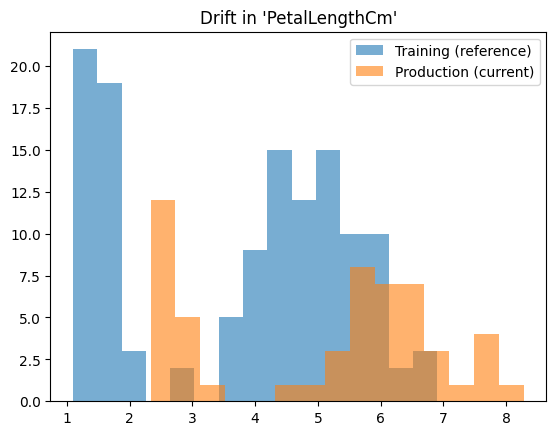

In [26]:
plt.hist(reference["PetalLengthCm"], alpha=0.6, label="Training (reference)", bins=15)
plt.hist(production["PetalLengthCm"], alpha=0.6, label="Production (current)", bins=15)
plt.legend(); plt.title("Drift in 'PetalLengthCm'"); plt.show()

**Concept drift** means the relationship between inputs and the label changes (even if the inputs look the same). We can only see it when true labels arrive, by tracking accuracy over time.

In [27]:
# Concept drift demo: labels change for the same inputs, so accuracy falls
y_concept = yte.copy()
mask = Xte["PetalWidthCm"] > 1.5          # the "rule" changes for these rows
shift_map = {"setosa": "versicolor", "versicolor": "virginica", "virginica": "setosa"}
y_concept[mask] = y_concept[mask].map(shift_map)
print("Accuracy with original labels :", round(accuracy_score(yte, pkg_model.predict(Xte)), 3))
print("Accuracy after concept drift  :", round(accuracy_score(y_concept, pkg_model.predict(Xte)), 3))

Accuracy with original labels : 0.963
Accuracy after concept drift  : 0.648


### 4.2 Optional: Evidently drift report
Evidently builds a ready-made HTML drift dashboard. Its API changes between versions, so this cell is wrapped to fail gracefully.

In [28]:
!pip install -q evidently
try:
    from evidently.report import Report
    from evidently.metric_preset import DataDriftPreset
    rep = Report(metrics=[DataDriftPreset()])
    rep.run(reference_data=reference, current_data=production)
    rep.save_html("evidently_drift_report.html")
    print("Saved evidently_drift_report.html (open it in a browser)")
except Exception:
    try:
        from evidently import Report
        from evidently.presets import DataDriftPreset
        snap = Report([DataDriftPreset()]).run(production, reference)
        snap.save_html("evidently_drift_report.html")
        print("Saved evidently_drift_report.html (open it in a browser)")
    except Exception as e:
        print("Evidently skipped:", type(e).__name__, "- the manual KS/PSI report above is enough for this lab")

Evidently skipped: ModuleNotFoundError - the manual KS/PSI report above is enough for this lab


### 4.3 Logging and alerting
Production systems log every prediction and raise **alerts** when metrics cross a threshold. Tools: **Prometheus** (collect metrics), **Grafana** (dashboards and alerts).

In [29]:
logging.basicConfig(filename="model_monitor.log", level=logging.INFO,
                    format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("monitor")

def send_alert(msg):
    print("ALERT:", msg)             # in real life: email, Slack, PagerDuty
    log.warning(msg)

# Log some predictions
for i in range(5):
    pred = pkg_model.predict(Xte.iloc[[i]])[0]
    log.info(f"prediction request={i} output={pred}")

# Check drift report and alert
drifted = drift_report[drift_report["drift"] == "YES"]["feature"].tolist()
if drifted:
    send_alert(f"Data drift detected in features: {drifted}")

print("\nLog file content:")
print(open("model_monitor.log").read())

ALERT: Data drift detected in features: ['PetalLengthCm']

Log file content:
2026-10-28 10:28:12,957 | INFO | prediction request=0 output=versicolor
2026-10-28 10:28:12,964 | INFO | prediction request=1 output=setosa
2026-10-28 10:28:12,970 | INFO | prediction request=2 output=versicolor
2026-10-28 10:28:12,973 | INFO | prediction request=3 output=versicolor
2026-10-28 10:28:12,978 | INFO | prediction request=4 output=versicolor
2026-10-28 10:28:12,987 | WARNING | Data drift detected in features: ['PetalLengthCm']



### 4.4 Retraining strategies: scheduled vs event-driven
* **Scheduled:** retrain every fixed period (daily, weekly). Simple, but may retrain when not needed.
* **Event-driven:** retrain only when drift or a performance drop is detected. Cheaper and more responsive.

In [30]:
def retrain(reason):
    print(f"Retraining triggered by: {reason}")
    # use the drifted production data (with true labels) together with old training data
    X_new = pd.concat([Xtr, production]); y_new = pd.concat([ytr, yte])
    return RandomForestClassifier(n_estimators=50, random_state=42).fit(X_new, y_new)

# 1) Scheduled: runs when the schedule fires (here: simulate "7 days passed")
days_since_last_training = 7
if days_since_last_training >= 7:
    scheduled_model = retrain("weekly schedule")

# 2) Event-driven: runs only if drift is found
if len(drifted) > 0:
    event_model = retrain(f"drift in {drifted}")

print("Accuracy on drifted production data -> old model:", round(accuracy_score(yte, pkg_model.predict(production)), 3),
      "| retrained model:", round(accuracy_score(yte, event_model.predict(production)), 3))

Retraining triggered by: weekly schedule
Retraining triggered by: drift in ['PetalLengthCm']
Accuracy on drifted production data -> old model: 0.704 | retrained model: 1.0


### 4.5 Bias and fairness monitoring
We compare model performance across **groups**. A big gap means the model treats groups unequally. (Here the groups are made-up: small vs large sepals.)

In [31]:
group = np.where(Xte["SepalLengthCm"] > Xte["SepalLengthCm"].median(), "large_sepal", "small_sepal")
preds = pkg_model.predict(Xte)

fair = pd.DataFrame({"group": group, "correct": preds == yte.values})
summary = fair.groupby("group")["correct"].agg(accuracy="mean", count="count")
print(summary)

gap = summary["accuracy"].max() - summary["accuracy"].min()
print(f"\nAccuracy gap between groups: {gap:.3f}")
print("Fairness check:", "PASS" if gap < 0.10 else "FAIL (investigate the data and model)")

             accuracy  count
group                       
large_sepal  0.962963     27
small_sepal  0.962963     27

Accuracy gap between groups: 0.000
Fairness check: PASS


### 4.6 Cost optimization: serverless vs dedicated infrastructure
| | Serverless (e.g. AWS Lambda) | Dedicated server / GPU |
|---|---|---|
| Pay for | Only per request | 24/7 uptime |
| Best when | Low or spiky traffic | Steady, high traffic |
| Downside | Cold starts, size limits | Idle cost |

In [32]:
# Simple break-even calculator (numbers are illustrative)
cost_per_1k_requests_serverless = 0.20      # USD
dedicated_server_monthly = 70.0             # USD

for monthly_requests in [10_000, 100_000, 500_000, 1_000_000, 5_000_000]:
    serverless = monthly_requests / 1000 * cost_per_1k_requests_serverless
    cheaper = "serverless" if serverless < dedicated_server_monthly else "dedicated"
    print(f"{monthly_requests:>9,} req/month | serverless ${serverless:>8.2f} | dedicated ${dedicated_server_monthly:.2f} | cheaper: {cheaper}")

   10,000 req/month | serverless $    2.00 | dedicated $70.00 | cheaper: serverless
  100,000 req/month | serverless $   20.00 | dedicated $70.00 | cheaper: serverless
  500,000 req/month | serverless $  100.00 | dedicated $70.00 | cheaper: dedicated
1,000,000 req/month | serverless $  200.00 | dedicated $70.00 | cheaper: dedicated
5,000,000 req/month | serverless $ 1000.00 | dedicated $70.00 | cheaper: dedicated


---
# Section 5: Advanced Topics and Case Studies (Unit V)

**Topics:** scaling ML systems, privacy and security (federated learning, differential privacy), edge ML (TFLite, ONNX Runtime), case studies, ethics and compliance (GDPR, explainability).

### 5.1 Scaling ML systems
**Microservices:** model served as its own small API, scaled independently.
**Distributed / parallel training:** split the work across cores or machines.

In [33]:
# Microservice: a minimal model-serving API (Flask). The file is written here, run it in a terminal with: python serve.py
serve_code = '''from flask import Flask, request, jsonify
import joblib, numpy as np

app = Flask(__name__)
model = joblib.load("models/model.joblib")

@app.route("/health")
def health():
    return {"status": "ok"}

@app.route("/predict", methods=["POST"])
def predict():
    features = np.array(request.json["features"]).reshape(1, -1)
    return jsonify({"prediction": str(model.predict(features)[0])})

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)
'''
open("serve.py", "w").write(serve_code)
print(serve_code)
print("Test it with:  curl -X POST localhost:5000/predict -H 'Content-Type: application/json' -d '{\"features\": [5.1, 3.5, 1.4, 0.2]}'")

from flask import Flask, request, jsonify
import joblib, numpy as np

app = Flask(__name__)
model = joblib.load("models/model.joblib")

@app.route("/health")
def health():
    return {"status": "ok"}

@app.route("/predict", methods=["POST"])
def predict():
    features = np.array(request.json["features"]).reshape(1, -1)
    return jsonify({"prediction": str(model.predict(features)[0])})

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)

Test it with:  curl -X POST localhost:5000/predict -H 'Content-Type: application/json' -d '{"features": [5.1, 3.5, 1.4, 0.2]}'


In [34]:
# Parallel training: the same model, 1 core vs all cores
Xb = np.random.rand(30_000, 20); yb = (Xb[:, :5].sum(axis=1) > 2.5).astype(int)

for n_jobs in [1, -1]:
    t0 = time.time()
    RandomForestClassifier(n_estimators=150, n_jobs=n_jobs, random_state=0).fit(Xb, yb)
    print(f"n_jobs={n_jobs:>2} -> {time.time() - t0:.2f} s")

n_jobs= 1 -> 28.57 s
n_jobs=-1 -> 4.51 s


In [35]:
# Training on data that does not fit in memory: learn in small batches with partial_fit
from sklearn.linear_model import SGDClassifier

sgd = SGDClassifier(random_state=0)
classes = np.unique(ya)
for start in range(0, len(Xtr), 30):                         # pretend each batch arrives separately
    batch = slice(start, start + 30)
    sgd.partial_fit(Xtr.iloc[batch], ytr.iloc[batch], classes=classes)
print("Incremental model accuracy:", round(accuracy_score(yte, sgd.predict(Xte)), 3))

Incremental model accuracy: 0.685


### 5.2 Privacy: Federated Learning
Data stays on each client (phone, hospital, bank). Only **model weights** are sent to a server and averaged.

In [36]:
# 3 clients, each with its own private data shard
clients = np.array_split(np.random.default_rng(1).permutation(len(Xtr)), 3)
coefs, intercepts = [], []
for k, idx in enumerate(clients):
    local = LogisticRegression(max_iter=500).fit(Xtr.iloc[idx], ytr.iloc[idx])
    coefs.append(local.coef_); intercepts.append(local.intercept_)
    print(f"Client {k+1}: trained on {len(idx)} private rows, local accuracy on test = {accuracy_score(yte, local.predict(Xte)):.3f}")

# Server: average weights (FedAvg). Raw data never leaves the clients
global_model = LogisticRegression(max_iter=500).fit(Xtr, ytr)    # initialize with all classes
global_model.coef_ = np.mean(coefs, axis=0)
global_model.intercept_ = np.mean(intercepts, axis=0)
print("\nFederated (averaged) model accuracy:", round(accuracy_score(yte, global_model.predict(Xte)), 3))

Client 1: trained on 42 private rows, local accuracy on test = 0.870
Client 2: trained on 42 private rows, local accuracy on test = 0.926
Client 3: trained on 42 private rows, local accuracy on test = 0.926

Federated (averaged) model accuracy: 0.907


### 5.3 Privacy: Differential Privacy
Add calibrated **noise** to results so no single person's record can be identified. Smaller epsilon means more privacy and more noise.

In [37]:
ages = np.random.default_rng(2).integers(20, 60, size=500)          # sensitive data
true_mean = ages.mean()
sensitivity = (60 - 20) / len(ages)                                    # max change from one person

for epsilon in [0.01, 0.1, 1.0, 10.0]:
    noisy = true_mean + np.random.laplace(0, sensitivity / epsilon)
    print(f"epsilon={epsilon:>5} | true mean {true_mean:.2f} | private mean {noisy:.2f} | error {abs(noisy - true_mean):.3f}")

epsilon= 0.01 | true mean 39.74 | private mean 32.40 | error 7.339
epsilon=  0.1 | true mean 39.74 | private mean 39.72 | error 0.014
epsilon=  1.0 | true mean 39.74 | private mean 39.84 | error 0.102
epsilon= 10.0 | true mean 39.74 | private mean 39.74 | error 0.000


**Security checklist for ML:** encrypt data at rest and in transit, control access to models, validate inputs (adversarial examples), never log personal data, scan dependencies.

### 5.4 Edge ML: ONNX Runtime and TFLite
Edge devices (phones, IoT) need small, fast, offline models. We reuse the ONNX model from Section 3.3 and measure speed.

In [38]:
sess = ort.InferenceSession("models/model.onnx")
sample = Xte.values.astype(np.float32)

def avg_ms(fn, n=200):
    t0 = time.time()
    for _ in range(n): fn()
    return (time.time() - t0) / n * 1000

print(f"sklearn  : {avg_ms(lambda: pkg_model.predict(sample)):.2f} ms per batch")
print(f"ONNX RT  : {avg_ms(lambda: sess.run(None, {'input': sample})):.2f} ms per batch")
print("Model file size:", os.path.getsize('models/model.onnx') // 1024, "KB")

sklearn  : 5.59 ms per batch
ONNX RT  : 0.41 ms per batch
Model file size: 31 KB


In [39]:
# TFLite (optional, needs TensorFlow). Skipped automatically if TensorFlow is missing.
try:
    import tensorflow as tf
    keras_model = tf.keras.Sequential([tf.keras.layers.Input(shape=(4,)),
                                       tf.keras.layers.Dense(8, activation="relu"),
                                       tf.keras.layers.Dense(3, activation="softmax")])
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]          # quantization for a smaller model
    open("models/model.tflite", "wb").write(converter.convert())
    print("TFLite model size:", os.path.getsize("models/model.tflite"), "bytes")
except ImportError:
    print("TensorFlow not installed, skipping TFLite. (Install with: pip install tensorflow)")

TensorFlow not installed, skipping TFLite. (Install with: pip install tensorflow)


### 5.5 Ethics and compliance: GDPR and explainability
**GDPR essentials:** lawful basis and consent, data minimisation, right to access and deletion, right to explanation for automated decisions.
**Explainability** shows *why* a model decided something. Below: which features matter most (permutation importance).

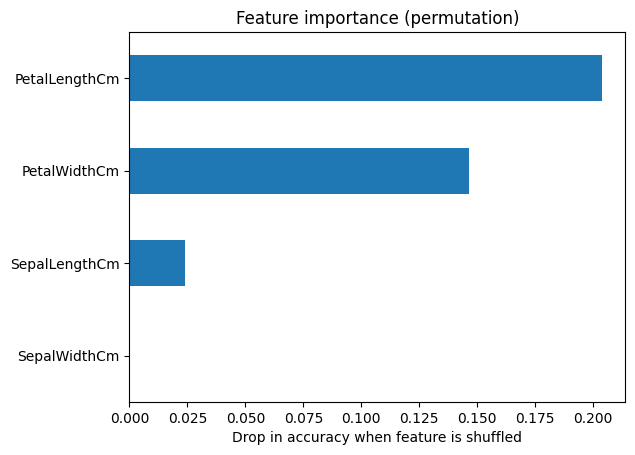

In [40]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(pkg_model, Xte, yte, n_repeats=10, random_state=0)
imp_df = pd.Series(imp.importances_mean, index=Xte.columns).sort_values()
imp_df.plot(kind="barh", title="Feature importance (permutation)")
plt.xlabel("Drop in accuracy when feature is shuffled"); plt.show()

### 5.6 Case studies
| Company | MLOps lesson |
|---|---|
| **Netflix** | Recommendation models retrained continuously; heavy A/B testing for every change; feature and experiment platforms |
| **Uber** | *Michelangelo* platform: one end-to-end system for features, training, deployment and monitoring (ETA, pricing, fraud) |
| **Airbnb** | *Bighead* platform and feature store (Zipline): reproducible features shared across teams (search ranking, pricing) |

**Discussion:** Which parts of Sections 2 to 4 (versioning, CI/CD, monitoring, feature store) does each company's platform automate?

---
# Section 6: Day 4, Final Assessment and Project

## 6.1 Quick self-assessment (answer in your notebook before checking)
1. Name three differences between DevOps and MLOps.
2. What is the difference between data drift and concept drift?
3. Why do we keep `.dvc` files in Git and not the data itself?
4. What do MLflow tracking and the MLflow registry each store?
5. Give one reason to use ONNX and one reason to use Docker.
6. Scheduled vs event-driven retraining: when would you choose each?
7. What does FedAvg send to the server, and what does it keep private?
8. Name two GDPR rights relevant to ML systems.

## 6.2 Final project: end-to-end MLOps pipeline
One cell runs the whole lifecycle: **data validation, training with tracking, quality gate, registry, ONNX packaging, drift monitoring, and a retraining decision.**
Edit `MY_PARAMS` and run again to see how experiments are tracked.

In [41]:
# ============ END-TO-END MLOPS PIPELINE ============
MY_PARAMS = {"n_estimators": 80, "max_depth": 6}
ACCURACY_GATE = 0.85

# 1. DATA: load and validate
data_df = pd.read_csv("data/iris.csv")
assert data_df.isnull().sum().sum() == 0, "Data validation failed"
feature_cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
Xp, yp = data_df[feature_cols], data_df["Species"]
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, yp, test_size=0.3, random_state=42, stratify=yp)
print("1. Data validated:", Xp.shape)

# 2. TRAIN + TRACK with MLflow
mlflow.set_experiment("final-project")
with mlflow.start_run(run_name="final_pipeline") as run:
    final_model = RandomForestClassifier(**MY_PARAMS, random_state=42).fit(Xp_tr, yp_tr)
    final_acc = accuracy_score(yp_te, final_model.predict(Xp_te))
    mlflow.log_params(MY_PARAMS); mlflow.log_metric("accuracy", final_acc)
    mlflow.sklearn.log_model(final_model, "model", serialization_format="cloudpickle")
    final_run_id = run.info.run_id
print(f"2. Trained and tracked. Accuracy = {final_acc:.3f}")

# 3. QUALITY GATE (this is the test step of CI/CD)
if final_acc < ACCURACY_GATE:
    raise SystemExit("3. Quality gate FAILED, model not promoted")
print("3. Quality gate passed")

# 4. REGISTER the model version
reg = mlflow.register_model(f"runs:/{final_run_id}/model", "final-iris-model")
print("4. Registered:", reg.name, "version", reg.version)

# 5. PACKAGE as ONNX
onx = convert_sklearn(final_model, initial_types=[("input", FloatTensorType([None, 4]))],
                      options={id(final_model): {"zipmap": False}})
open("models/final_model.onnx", "wb").write(onx.SerializeToString())
s = ort.InferenceSession("models/final_model.onnx")
assert np.array_equal(s.run(None, {"input": Xp_te.values.astype(np.float32)})[0], final_model.predict(Xp_te))
print("5. Packaged to ONNX and verified")

# 6. MONITOR: check live data for drift
live = Xp_te.copy(); live["SepalWidthCm"] += np.random.default_rng(9).normal(1.0, 0.2, len(live))
drift_flags = {c: ks_2samp(Xp_tr[c], live[c])[1] < 0.05 for c in Xp.columns}
print("6. Drift check:", drift_flags)

# 7. DECIDE: retrain if drift found (event-driven)
if any(drift_flags.values()):
    print("7. Drift detected, retraining triggered")
    final_model = RandomForestClassifier(**MY_PARAMS, random_state=42).fit(pd.concat([Xp_tr, live]), pd.concat([yp_tr, yp_te]))
else:
    print("7. No drift, keep current model")
print("\nPipeline complete.")

1. Data validated: (180, 4)
2. Trained and tracked. Accuracy = 0.944
3. Quality gate passed
4. Registered: final-iris-model version 1
5. Packaged to ONNX and verified
6. Drift check: {'SepalLengthCm': np.False_, 'SepalWidthCm': np.True_, 'PetalLengthCm': np.False_, 'PetalWidthCm': np.False_}
7. Drift detected, retraining triggered

Pipeline complete.


2026/10/28 10:28:48 INFO mlflow.tracking.fluent: Experiment with name 'final-project' does not exist. Creating a new experiment.
2026/10/28 10:28:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/28 10:28:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Successfully registered model 'final-iris-model'.
2026/10/28 10:29:01 WARNING mlflow.tracking._model_registry.fluent: Run with id 223287997ed147db98bd49753dac2827 has no artifacts at artifact path 'model', registering model based on models:/m-91231d4ec5ce440c887d6f4b36752191 instead
Created version '1' of model 'final-iris-model'.


## 6.3 Project deliverables checklist
- [ ] Data versioned with DVC (two versions, tags `v1` and `v2`)
- [ ] Experiments tracked in MLflow (3 or more runs compared)
- [ ] Model registered and exported to ONNX
- [ ] Docker files and CI workflow (`ci.yml`) created, tests passing
- [ ] Drift report and alert demonstrated
- [ ] Short README: how to reproduce, versions used, team roles

## 6.4 Demo and viva tips
* Show `mlflow ui` (run `!mlflow ui --backend-store-uri sqlite:///mlflow.db` in a terminal) with your compared runs.
* Explain one design choice per unit.
* Be ready to answer: *what would you do if accuracy dropped in production next month?*